## 02 Solar Photon Flux by Location and Hour

This notebook calculates the **total solar photon flux (photons per m² per hour)** reaching a horizontal surface for any latitude/longitude, date and hour interval. It then builds a table for the 10 iFlex municipalities that joins onto `combined_data.parquet` as a sunlight covariate.

**Method**
1. The sun's position comes from the NREL Solar Position Algorithm, and clear-sky global horizontal irradiance (GHI, W/m²) from the Ineichen-Perez model with monthly Linke turbidity, both via `pvlib`.
2. GHI is sampled every minute and summed into energy per hour (J/m²).
3. Energy is converted to photons with a photons-per-joule factor from the ASTM G173-03 (AM1.5) reference solar spectrum, 280-4000 nm. A PAR (400-700 nm) count is also given.

**Assumptions**
* **Clear sky only** (no clouds), so this is an upper bound on sunlight.
* Horizontal surface, no terrain shading.
* Fixed AM1.5 spectral shape. At low winter sun angles the true spectrum is redder, so photons per joule is a few percent higher. Energy (Wh/m²) is not affected.
* Hour h (1-24) = local Europe/Oslo wall-clock interval [h-1, h), the same as the `Hour` column in the dataset.
* Polar night: Tromsø (~27 Nov - 15 Jan) and Bodø (~5 Dec - 7 Jan) get 0.

Requirements: `pip install polars pvlib matplotlib`

In [3]:
#Load required libraries
import os
import datetime as dt
from functools import lru_cache
from typing import Iterable

import numpy as np
import pandas as pd
import polars as pl
import pvlib

import matplotlib.pyplot as plt

#Get current working directory (.\\notebooks) and parent folder to access (.\\Data)
cwd = os.getcwd()
parent = os.path.dirname(cwd)

### Constants and iFlex locations
The dataset only records city, so each municipality gets city-centre coordinates. The Region column and its weather station are kept for reference. Moving a few km changes hourly flux by well under 1 %.

In [4]:
TZ = "Europe/Oslo"
AVOGADRO = 6.02214076e23
H_PLANCK = 6.62607015e-34
C_LIGHT = 2.99792458e8

# lat, lon (deg), altitude (m), region, weather station used by iFlex for that region
LOCATIONS: dict[str, dict] = {
    "Oslo":       dict(lat=59.9139, lon=10.7522, alt=23,  region="Oslo",      station="Oslo-Blindern"),
    "Asker":      dict(lat=59.8333, lon=10.4392, alt=100, region="Oslo",      station="Oslo-Blindern"),
    "Bærum":      dict(lat=59.8940, lon=10.5463, alt=20,  region="Oslo",      station="Oslo-Blindern"),
    "Drammen":    dict(lat=59.7439, lon=10.2045, alt=5,   region="Oslo",      station="Oslo-Blindern"),
    "Lillestrøm": dict(lat=59.9560, lon=11.0492, alt=105, region="Oslo",      station="Oslo-Blindern"),
    "Bergen":     dict(lat=60.3913, lon=5.3221,  alt=12,  region="Bergen",    station="Bergen-Florida"),
    "Stavanger":  dict(lat=58.9700, lon=5.7331,  alt=10,  region="Stavanger", station="Stavanger-Våland"),
    "Trondheim":  dict(lat=63.4305, lon=10.3951, alt=20,  region="Trondheim", station="Trondheim-Risvollan"),
    "Bodø":       dict(lat=67.2804, lon=14.4049, alt=10,  region="Bodø",      station="Bodø-Skivika"),
    "Tromsø":     dict(lat=69.6492, lon=18.9553, alt=10,  region="Tromsø",    station="Tromsø"),
}

### Step 1: photons per joule from the reference solar spectrum
Each photon carries energy $E = hc/\lambda$, so the number of photons per joule of sunlight is $\int E_\lambda \, \lambda/(hc)\, d\lambda \; / \int E_\lambda \, d\lambda$ over the ASTM G173 global spectrum.

In [5]:
@lru_cache(maxsize=None)
def photons_per_joule() -> dict[str, float]:
    """Photon-per-joule factors from the ASTM G173-03 global spectrum."""
    s = pvlib.spectrum.get_reference_spectra(standard="ASTM G173-03")
    wl = s.index.to_numpy(dtype=float)            # nm
    e = s["global"].to_numpy(dtype=float)         # W m^-2 nm^-1
    n = e * (wl * 1e-9) / (H_PLANCK * C_LIGHT)    # photons s^-1 m^-2 nm^-1
    par = (wl >= 400) & (wl <= 700)
    total_e = np.trapezoid(e, wl)
    return {
        "full": np.trapezoid(n, wl) / total_e,
        "par": np.trapezoid(n[par], wl[par]) / total_e,
        "par_energy_fraction": np.trapezoid(e[par], wl[par]) / total_e,
    }

In [6]:
factors = photons_per_joule()
print(f"Full spectrum : {factors['full']:.3e} photons per J")
print(f"PAR 400-700 nm: {factors['par']:.3e} photons per J of total GHI")
print(f"PAR share of energy: {factors['par_energy_fraction']:.1%}")

Full spectrum : 4.304e+18 photons per J
PAR 400-700 nm: 1.191e+18 photons per J of total GHI
PAR share of energy: 43.0%


### Step 2: hourly photon flux function
`photon_flux()` takes a lat/lon (or an iFlex `location` name), dates (one date, a list, or a `(start, end)` tuple) and the hours you want. It returns one row per Date x Hour with:
* `ghi_Wh_m2`: clear-sky energy in the hour
* `photons_m2`: full-spectrum photons per m² in the hour
* `par_photons_m2`, `par_mol_m2`: PAR photons per m² (count and mol)
* `sun_minutes`: minutes with the sun above the horizon

In [9]:
def _date_list(dates) -> list[dt.date]:
    if isinstance(dates, tuple) and len(dates) == 2:
        start, end = (pd.Timestamp(d).date() for d in dates)
        return list(pd.date_range(start, end, freq="D").date)
    if isinstance(dates, (str, dt.date, pd.Timestamp)):
        return [pd.Timestamp(dates).date()]
    return [pd.Timestamp(d).date() for d in dates]


def photon_flux(
    lat: float | None = None,
    lon: float | None = None,
    dates=None,
    hours: Iterable[int] = range(1, 25),
    altitude: float = 0.0,
    location: str | None = None,
    tz: str = TZ,
    step_minutes: int = 1,
) -> pl.DataFrame:
    """Hourly clear-sky photon flux on a horizontal surface.

    lat, lon   : decimal degrees (N, E positive). Or give `location` = one of LOCATIONS.
    dates      : a date, a list of dates, or a (start, end) tuple (inclusive).
    hours      : iFlex Hour numbers 1-24 (Hour h = local [h-1, h)). Default all.
    altitude   : metres above sea level.
    Returns one row per Date x Hour with:
      ghi_Wh_m2        clear-sky energy in the hour (Wh/m^2)
      photons_m2       full-spectrum (280-4000 nm) photons per m^2 in the hour
      par_photons_m2   PAR (400-700 nm) photons per m^2 in the hour
      par_mol_m2       PAR in mol photons per m^2 in the hour
      sun_minutes      minutes with the sun above the horizon
    """
    if location is not None:
        loc = LOCATIONS[location]
        lat, lon, altitude = loc["lat"], loc["lon"], loc["alt"]
    if lat is None or lon is None or dates is None:
        raise ValueError("Need lat/lon (or location) and dates.")

    days = _date_list(dates)
    hours = sorted(set(int(h) for h in hours))
    step = pd.Timedelta(minutes=step_minutes)

    # Minute grid covering every local day, built in UTC then labelled locally.
    start = pd.Timestamp(min(days)).tz_localize(tz) - pd.Timedelta(hours=1)
    end = pd.Timestamp(max(days) + dt.timedelta(days=1)).tz_localize(tz) + pd.Timedelta(hours=1)
    edges = pd.date_range(start.tz_convert("UTC"), end.tz_convert("UTC"), freq=step)
    mids = edges + step / 2                       # sample at bin midpoints

    site = pvlib.location.Location(lat, lon, tz="UTC", altitude=altitude)
    cs = site.get_clearsky(mids, model="ineichen")
    zen = site.get_solarposition(mids)["apparent_zenith"].to_numpy()

    local = edges.tz_convert(tz)                  # bin start in local time
    f = photons_per_joule()
    wall = pl.Series("wall", local.tz_localize(None).to_numpy())   # naive local wall-clock
    df = pl.DataFrame({
        "Date": wall.dt.date(),
        "Hour": (wall.dt.hour() + 1).cast(pl.Int32),
        "ghi": cs["ghi"].clip(lower=0).to_numpy(),
        "up": (zen < 90).astype(np.int32),
    })
    sec = step.total_seconds()
    out = (
        df.filter(pl.col("Date").is_in(days) & pl.col("Hour").is_in(hours))
        .group_by("Date", "Hour")
        .agg(
            (pl.col("ghi").sum() * sec).alias("J_m2"),
            (pl.col("up").sum() * step_minutes).alias("sun_minutes"),
        )
        .with_columns(
            (pl.col("J_m2") / 3600).alias("ghi_Wh_m2"),
            (pl.col("J_m2") * f["full"]).alias("photons_m2"),
            (pl.col("J_m2") * f["par"]).alias("par_photons_m2"),
            (pl.col("J_m2") * f["par"] / AVOGADRO).alias("par_mol_m2"),
        )
        .drop("J_m2")
        .with_columns(pl.col("Hour").cast(pl.Int32))
        .sort("Date", "Hour")
        .select("Date", "Hour", "ghi_Wh_m2", "photons_m2", "par_photons_m2", "par_mol_m2", "sun_minutes")
    )
    return out

In [10]:
def total_photons(lat=None, lon=None, date=None, hours=range(1, 25), **kw) -> float:
    """Total full-spectrum photons per m^2 over the chosen hours of one or more dates."""
    return float(photon_flux(lat, lon, date, hours=hours, **kw)["photons_m2"].sum())


def municipality_flux_table(start="2020-01-06", end="2021-03-26", dates=None) -> pl.DataFrame:
    """Flux for every iFlex municipality. Keys: Municipality, Region, Date, Hour."""
    frames = []
    for name, loc in LOCATIONS.items():
        frames.append(
            photon_flux(location=name, dates=dates if dates is not None else (start, end))
            .with_columns(pl.lit(name).alias("Municipality"), pl.lit(loc["region"]).alias("Region"))
        )
    return pl.concat(frames).select("Municipality", "Region", pl.exclude("Municipality", "Region"))

### Example 1: one location, one date, an hour interval
Oslo on midsummer, Hours 10-15 (09:00-15:00 local).

In [11]:
oslo_midsummer = photon_flux(59.9139, 10.7522, "2020-06-21", hours=range(10, 16), altitude=23)
oslo_midsummer

Date,Hour,ghi_Wh_m2,photons_m2,par_photons_m2,par_mol_m2,sun_minutes
date,i32,f64,f64,f64,f64,i32
2020-06-21,10,531.127058,8.2294e24,2.2766e24,3.780396,60
2020-06-21,11,633.402749,9.8141e24,2.7150e24,4.508362,60
2020-06-21,12,710.152583,1.1003e25,3.0440e24,5.054643,60
2020-06-21,13,755.742937,1.1710e25,3.2394e24,5.379141,60
2020-06-21,14,766.877044,1.1882e25,3.2871e24,5.45839,60
2020-06-21,15,742.75408,1.1508e25,3.1837e24,5.28669,60


In [12]:
print(f"Total photons, Oslo 2020-06-21, 09:00-15:00: {oslo_midsummer['photons_m2'].sum():.3e} per m^2")

Total photons, Oslo 2020-06-21, 09:00-15:00: 6.415e+25 per m^2


### Example 2: whole-day totals across the 10 municipalities
Winter solstice, spring equinox and summer solstice, in units of 10²⁴ photons/m² per day.

In [13]:
days = ["2020-12-21", "2020-03-20", "2020-06-21"]
daily = pl.DataFrame([
    {"Municipality": name, **{d: round(total_photons(location=name, date=d) / 1e24, 2) for d in days}}
    for name in LOCATIONS
])
daily

Municipality,2020-12-21,2020-03-20,2020-06-21
str,f64,f64,f64
"""Oslo""",3.65,51.95,117.41
"""Asker""",3.69,52.01,118.2
"""Bærum""",3.68,51.04,117.92
"""Drammen""",3.92,52.59,118.91
"""Lillestrøm""",3.61,52.02,118.13
"""Bergen""",3.04,48.58,121.21
"""Stavanger""",4.49,51.5,121.3
"""Trondheim""",0.87,49.81,124.05
"""Bodø""",0.0,42.29,124.33


### Example 3: daily profile plot
Hourly photon flux on one winter and one summer day for a south, middle and northern city.

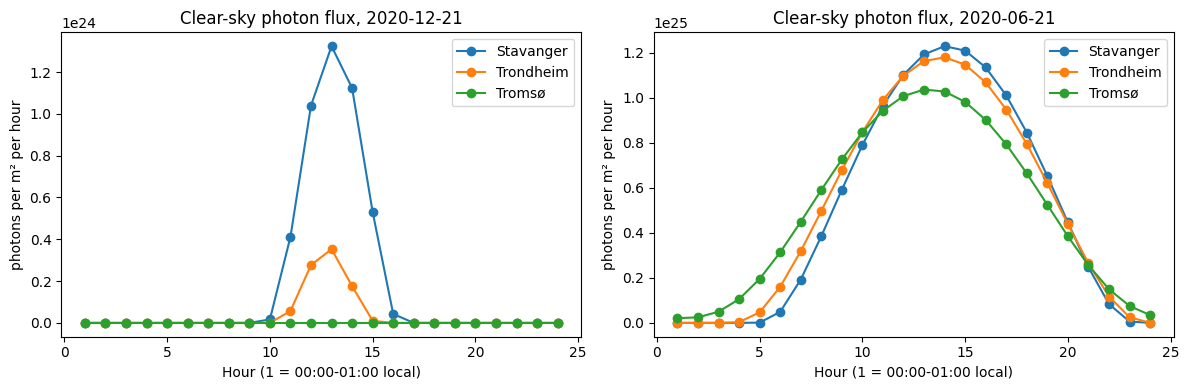

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, d in zip(axes, ["2020-12-21", "2020-06-21"]):
    for name in ["Stavanger", "Trondheim", "Tromsø"]:
        df = photon_flux(location=name, dates=d)
        ax.plot(df["Hour"], df["photons_m2"], marker="o", label=name)
    ax.set_title(f"Clear-sky photon flux, {d}")
    ax.set_xlabel("Hour (1 = 00:00-01:00 local)")
    ax.set_ylabel("photons per m² per hour")
    ax.legend()
plt.tight_layout()
plt.show()

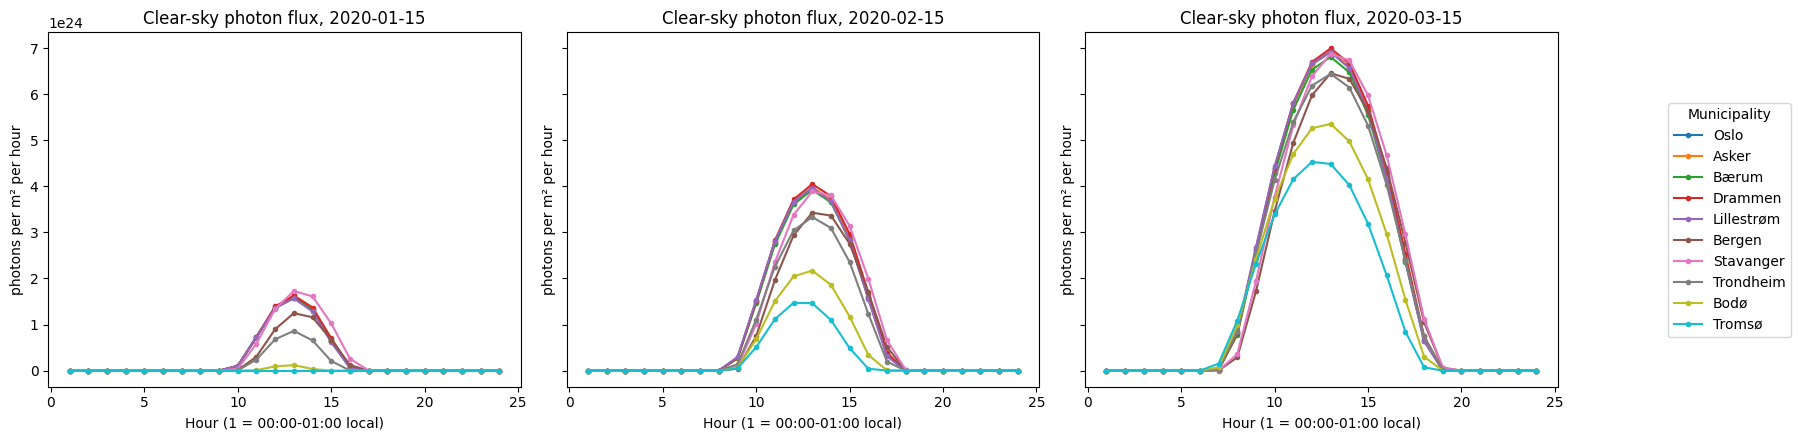

In [20]:
#Phase 1 ran 2020-01-06 to 2020-03-20: one representative day (the 15th) per month
phase1_dates = ["2020-01-15", "2020-02-15", "2020-03-15"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, d in zip(axes.flat, phase1_dates):
    for name in LOCATIONS:
        df = photon_flux(location=name, dates=d)
        ax.plot(df["Hour"], df["photons_m2"], marker="o", markersize=3, label=name)
    ax.set_title(f"Clear-sky photon flux, {d}")
    ax.set_xlabel("Hour (1 = 00:00-01:00 local)")
    ax.set_ylabel("photons per m² per hour")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right", title="Municipality")
plt.tight_layout(rect=(0, 0, 0.88, 1))
plt.show()

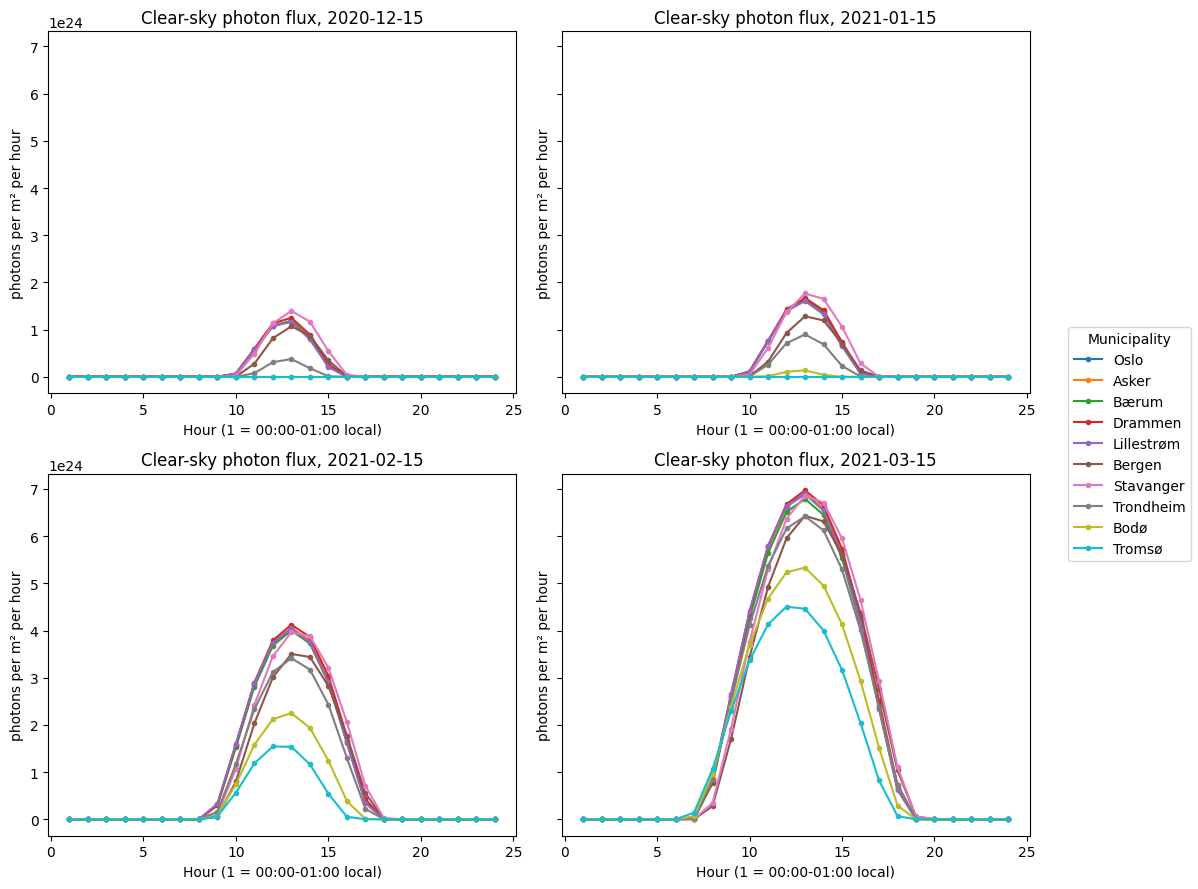

In [19]:
#Phase 2 ran 2020-12-01 to 2021-03-26: one representative day (the 15th) per month
phase2_dates = ["2020-12-15", "2021-01-15", "2021-02-15", "2021-03-15"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
for ax, d in zip(axes.flat, phase2_dates):
    for name in LOCATIONS:
        df = photon_flux(location=name, dates=d)
        ax.plot(df["Hour"], df["photons_m2"], marker="o", markersize=3, label=name)
    ax.set_title(f"Clear-sky photon flux, {d}")
    ax.set_xlabel("Hour (1 = 00:00-01:00 local)")
    ax.set_ylabel("photons per m² per hour")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right", title="Municipality")
plt.tight_layout(rect=(0, 0, 0.88, 1))
plt.show()

### Step 3: table for all municipalities on the experiment days, and join
`combined_data.parquet` has 191 unique experiment dates. Computing all 10 municipalities takes about a minute.

In [16]:
#Get file path to load into environment
file_path_combined = os.path.join(parent, "Data", "combined_data.parquet")

experiment_days = sorted(
    pl.scan_parquet(file_path_combined).select("Date").unique().collect()["Date"].to_list()
)
flux_df = municipality_flux_table(dates=experiment_days)
print(flux_df.shape)
flux_df.head()

FileNotFoundError: The system cannot find the path specified. (os error 3): c:/Users/Rudy_/Data/combined_data.parquet

In [12]:
#Join the flux columns onto the hourly data (lazy, so the 13.5M rows stay out of memory until needed)
hourly_with_flux = (
    pl.scan_parquet(file_path_combined)
    .join(flux_df.lazy().drop("Region"), on=["Municipality", "Date", "Hour"], how="left")
)

#Check that every hourly row found a match
hourly_with_flux.select(pl.len().alias("rows"), pl.col("photons_m2").null_count().alias("unmatched")).collect()

rows,unmatched
u32,u32
13515600,0


In [13]:
#Save the flux table for reuse
file_path_flux = os.path.join(parent, "Data", "solar_photon_flux_hourly.parquet")
flux_df.write_parquet(file_path_flux, compression="zstd")